# 🦠 COVID-19 Analytics Dashboard

**A comprehensive data analysis project** focused on understanding the global impact of COVID-19 through:
- 🧹 Data Cleaning & Preprocessing
- 📊 Exploratory Data Analysis (EDA)
- 📈 Trend & Growth Rate Analysis
- 🔬 Statistical Insights
- 🌍 Country-wise & India-specific Comparisons

**Libraries Used:** `pandas` | `numpy` | `matplotlib` | `seaborn`

**Author:** Vatsal Gajera

---

## 📦 Section 1 — Setup & Imports

In [1]:
# ── Core Libraries ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# ── Plot Configuration ───────────────────────────────────────────────────────
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#0f0f1a',
    'axes.facecolor': '#1a1a2e',
    'axes.labelcolor': '#e0e0e0',
    'axes.titlecolor': '#ffffff',
    'axes.edgecolor': '#444466',
    'axes.grid': True,
    'grid.color': '#2a2a4a',
    'xtick.color': '#cccccc',
    'ytick.color': '#cccccc',
    'text.color': '#e0e0e0',
    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
    'font.family': 'DejaVu Sans',
    'font.size': 10,
})

# ── Color Palette ─────────────────────────────────────────────────────────────
COLORS = {
    'confirmed': '#f4a261',
    'deaths':    '#e63946',
    'recovered': '#2a9d8f',
    'active':    '#457b9d',
    'new_cases': '#a8dadc',
}

print('✅ Libraries imported successfully!')
print(f'   pandas  {pd.__version__}')
print(f'   numpy   {np.__version__}')
print(f'   matplotlib {plt.matplotlib.__version__}')
print(f'   seaborn {sns.__version__}')

✅ Libraries imported successfully!
   pandas  3.0.3
   numpy   2.4.6
   matplotlib 3.10.9
   seaborn 0.13.2


---
## 📂 Section 2 — Data Loading

Loading 8 relevant datasets (CSVs + Excel) from `../data/` and `../excel/` folders.

In [2]:
# ── Load Global Datasets ──────────────────────────────────────────────────────
df_global   = pd.read_csv('../data/recent_covid_19_data.csv')
df_ts       = pd.read_csv('../data/time-series-19-covid-combined.csv')
df_conf     = pd.read_csv('../data/time_series_covid_19_confirmed.csv')
df_deaths   = pd.read_csv('../data/time_series_covid_19_deaths.csv')
df_recov    = pd.read_csv('../data/time_series_covid_19_recovered.csv')

# ── Load India-Specific Excel Datasets ───────────────────────────────────────
df_india      = pd.read_excel('../excel/Covid cases in India.xlsx')
df_coords     = pd.read_excel('../excel/Indian Coordinates.xlsx')
df_perday     = pd.read_excel('../excel/per_day_cases.xlsx')

# ── Summary Table ─────────────────────────────────────────────────────────────
datasets = {
    'recent_covid_19_data':           df_global,
    'time-series-19-covid-combined':  df_ts,
    'time_series_confirmed':          df_conf,
    'time_series_deaths':             df_deaths,
    'time_series_recovered':          df_recov,
    'Covid cases in India (Excel)':   df_india,
    'Indian Coordinates (Excel)':     df_coords,
    'per_day_cases (Excel)':          df_perday,
}

print(f'{'Dataset':<40} {'Rows':>7} {'Columns':>9}')
print('-' * 60)
for name, df in datasets.items():
    print(f'{name:<40} {df.shape[0]:>7,} {df.shape[1]:>9}')

Dataset                                     Rows   Columns
------------------------------------------------------------
recent_covid_19_data                       7,313         8
time-series-19-covid-combined             25,760         8
time_series_confirmed                        442        57
time_series_deaths                           442        57
time_series_recovered                        442        57
Covid cases in India (Excel)                  26         6
Indian Coordinates (Excel)                    35         3
per_day_cases (Excel)                         52         4


In [3]:
# ── Quick Preview of Primary Dataset ─────────────────────────────────────────
print('=== recent_covid_19_data.csv — First 5 Rows ===')
display(df_global.head())

print('\n=== time-series-19-covid-combined.csv — First 5 Rows ===')
display(df_ts.head())

print('\n=== Covid cases in India.xlsx — All Rows ===')
display(df_india.head(10))

=== recent_covid_19_data.csv — First 5 Rows ===


,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14.0,0.0,0.0
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6.0,0.0,0.0
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0.0,0.0,0.0



=== time-series-19-covid-combined.csv — First 5 Rows ===


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Recovered,Deaths
0,NaN,Thailand,15.0,101.0,2020-01-22,2,0,0
1,NaN,Thailand,15.0,101.0,2020-01-23,3,0,0
2,NaN,Thailand,15.0,101.0,2020-01-24,5,0,0
3,NaN,Thailand,15.0,101.0,2020-01-25,7,0,0
4,NaN,Thailand,15.0,101.0,2020-01-26,8,2,0



=== Covid cases in India.xlsx — All Rows ===


,S. No.,Name of State / UT,Total Confirmed cases (Indian National),Total Confirmed cases ( Foreign National ),Cured,Death
0,1,Andhra Pradesh,12,0,1,0
1,2,Chhattisgarh,6,0,0,0
2,3,Delhi,38,1,6,1
3,4,Gujarat,43,0,0,3
4,5,Haryana,16,14,11,0
5,6,Himachal Pradesh,4,0,0,1
6,7,Karnataka,20,0,3,2
7,8,Kerala,131,7,11,0
8,9,Madhya Pradesh,23,0,0,1
9,10,Maharashtra,144,3,15,4


---
## 🧹 Section 3 — Data Cleaning & Preprocessing

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# 3A — Clean the PRIMARY global dataset  (recent_covid_19_data.csv)
# ══════════════════════════════════════════════════════════════════════════════

df = df_global.copy()

# ── 1. Inspect missing values ────────────────────────────────────────────────
print('Missing values before cleaning:')
print(df.isnull().sum())

# ── 2. Fill missing Province/State with Country name ─────────────────────────
df['Province/State'] = df['Province/State'].fillna(df['Country/Region'])

# ── 3. Convert date columns ───────────────────────────────────────────────────
df['ObservationDate'] = pd.to_datetime(df['ObservationDate'], format='%m/%d/%Y')
df['Last Update']     = pd.to_datetime(df['Last Update'], format='mixed', dayfirst=False)

# ── 4. Remove duplicates ──────────────────────────────────────────────────────
before_dup = len(df)
df.drop_duplicates(inplace=True)
print(f'\nDuplicates removed: {before_dup - len(df)}')

# ── 5. Ensure numeric columns are correct type ────────────────────────────────
for col in ['Confirmed', 'Deaths', 'Recovered']:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# ── 6. Feature Engineering ───────────────────────────────────────────────────
df['Active']          = df['Confirmed'] - df['Deaths'] - df['Recovered']
df['Active']          = df['Active'].clip(lower=0)       # prevent negatives
df['Mortality_Rate']  = np.where(df['Confirmed'] > 0,
                                 (df['Deaths'] / df['Confirmed']) * 100, 0)
df['Recovery_Rate']   = np.where(df['Confirmed'] > 0,
                                 (df['Recovered'] / df['Confirmed']) * 100, 0)

print('\nMissing values after cleaning:')
print(df.isnull().sum())
print(f'\nFinal shape: {df.shape}')
display(df.head())

Missing values before cleaning:
SNo                   0
ObservationDate       0
Province/State     3093
Country/Region        0
Last Update           0
Confirmed             0
Deaths                0
Recovered             0
dtype: int64

Duplicates removed: 0

Missing values after cleaning:
SNo                0
ObservationDate    0
Province/State     0
Country/Region     0
Last Update        0
Confirmed          0
Deaths             0
Recovered          0
Active             0
Mortality_Rate     0
Recovery_Rate      0
dtype: int64

Final shape: (7313, 11)


,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered,Active,Mortality_Rate,Recovery_Rate
0,1,2020-01-22,Anhui,Mainland China,2020-01-22 17:00:00,1,0,0,1,0.0,0.0
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,14,0.0,0.0
2,3,2020-01-22,Chongqing,Mainland China,2020-01-22 17:00:00,6,0,0,6,0.0,0.0
3,4,2020-01-22,Fujian,Mainland China,2020-01-22 17:00:00,1,0,0,1,0.0,0.0
4,5,2020-01-22,Gansu,Mainland China,2020-01-22 17:00:00,0,0,0,0,0.0,0.0


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# 3B — Clean the TIME-SERIES dataset
# ══════════════════════════════════════════════════════════════════════════════

df_ts_clean = df_ts.copy()
df_ts_clean['Date']       = pd.to_datetime(df_ts_clean['Date'])
df_ts_clean['Province/State'] = df_ts_clean['Province/State'].fillna(df_ts_clean['Country/Region'])

for col in ['Confirmed', 'Recovered', 'Deaths']:
    df_ts_clean[col] = pd.to_numeric(df_ts_clean[col], errors='coerce').fillna(0).astype(int)

# Global daily totals (aggregate across all countries)
df_global_daily = (
    df_ts_clean
    .groupby('Date')[['Confirmed', 'Recovered', 'Deaths']]
    .sum()
    .reset_index()
    .sort_values('Date')
)
df_global_daily['Active']   = df_global_daily['Confirmed'] - df_global_daily['Deaths'] - df_global_daily['Recovered']
df_global_daily['New_Cases']= df_global_daily['Confirmed'].diff().fillna(0).clip(lower=0)
df_global_daily['Growth_Rate(%)'] = df_global_daily['Confirmed'].pct_change().mul(100).fillna(0)

print(f'Time-series daily range: {df_global_daily["Date"].min().date()} → {df_global_daily["Date"].max().date()}')
display(df_global_daily.tail())

Time-series daily range: 2020-01-22 → 2020-03-17


,Date,Confirmed,Recovered,Deaths,Active,New_Cases,Growth_Rate(%)
51,2020-03-13,145193,70251,5404,69538,16850.0,13.128881
52,2020-03-14,156097,72624,5819,77654,10904.0,7.510004
53,2020-03-15,167449,76034,6440,84975,11352.0,7.272401
54,2020-03-16,181531,78088,7126,96317,14082.0,8.409725
55,2020-03-17,197146,80840,7905,108401,15615.0,8.601837


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# 3C — Clean India Excel datasets
# ══════════════════════════════════════════════════════════════════════════════

# India state data — rename columns for convenience
df_india.columns = ['SNo', 'State', 'Confirmed_Indian', 'Confirmed_Foreign', 'Cured', 'Deaths']
df_india['Total_Confirmed'] = df_india['Confirmed_Indian'] + df_india['Confirmed_Foreign']
df_india['Active']          = df_india['Total_Confirmed'] - df_india['Cured'] - df_india['Deaths']
df_india['Active']          = df_india['Active'].clip(lower=0)

# Per-day cases
df_perday['Date']     = pd.to_datetime(df_perday['Date'])
df_perday.columns     = ['Date', 'Total_Cases', 'New_Cases', 'Days_After_100']
df_perday['New_Cases']= df_perday['New_Cases'].fillna(0).astype(int)

# Merge coordinates
df_coords.columns = ['State', 'Latitude', 'Longitude']
df_india_geo = df_india.merge(df_coords, on='State', how='left')

print('India state data (cleaned):')
display(df_india[['State','Total_Confirmed','Cured','Deaths','Active']].head(10))

India state data (cleaned):


,State,Total_Confirmed,Cured,Deaths,Active
0,Andhra Pradesh,12,1,0,11
1,Chhattisgarh,6,0,0,6
2,Delhi,39,6,1,32
3,Gujarat,43,0,3,40
4,Haryana,30,11,0,19
5,Himachal Pradesh,4,0,1,3
6,Karnataka,20,3,2,15
7,Kerala,138,11,0,127
8,Madhya Pradesh,23,0,1,22
9,Maharashtra,147,15,4,128


---
## 📐 Section 4 — Descriptive Statistics

In [7]:
# ── Latest snapshot per country (max observation date for each country) ───────
df_latest = (
    df.sort_values('ObservationDate')
    .groupby('Country/Region')
    .last()
    .reset_index()
)

numeric_cols = ['Confirmed', 'Deaths', 'Recovered', 'Active', 'Mortality_Rate', 'Recovery_Rate']

print('=== Descriptive Statistics (Latest per Country) ===')
display(df_latest[numeric_cols].describe().round(2))

print('\n=== NumPy-based Statistics (Confirmed Cases) ===')
confirmed = df_latest['Confirmed'].values
stats = {
    'Total Confirmed (Global)': int(np.sum(confirmed)),
    'Mean per Country':         round(float(np.mean(confirmed)), 2),
    'Median':                   round(float(np.median(confirmed)), 2),
    'Std Dev':                  round(float(np.std(confirmed)), 2),
    '25th Percentile':          round(float(np.percentile(confirmed, 25)), 2),
    '75th Percentile':          round(float(np.percentile(confirmed, 75)), 2),
    'Max (single country)':     int(np.max(confirmed)),
    'Min (single country)':     int(np.min(confirmed)),
}

for key, val in stats.items():
    print(f'  {key:<35}: {val:>12,}')

print('\n=== Global Totals ===')
total_confirmed = df_latest['Confirmed'].sum()
total_deaths    = df_latest['Deaths'].sum()
total_recovered = df_latest['Recovered'].sum()
total_active    = df_latest['Active'].sum()
print(f'  Confirmed : {total_confirmed:>12,}')
print(f'  Deaths    : {total_deaths:>12,}')
print(f'  Recovered : {total_recovered:>12,}')
print(f'  Active    : {total_active:>12,}')
print(f'  Mortality : {total_deaths/total_confirmed*100:.2f}%')
print(f'  Recovery  : {total_recovered/total_confirmed*100:.2f}%')

=== Descriptive Statistics (Latest per Country) ===


,Confirmed,Deaths,Recovered,Active,Mortality_Rate,Recovery_Rate
count,191.00,191.00,191.00,191.00,191.00,191.00
mean,888.61,40.73,84.88,762.99,1.51,5.11
std,4334.76,319.11,602.54,3611.41,4.86,14.79
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.00,0.00,0.00,2.00,0.00,0.00
50%,39.00,0.00,0.00,36.00,0.00,0.00
75%,174.00,1.00,4.00,154.50,1.05,2.33
max,47021.00,4032.00,6745.00,38549.00,50.00,100.00



=== NumPy-based Statistics (Confirmed Cases) ===
  Total Confirmed (Global)           :      169,724
  Mean per Country                   :       888.61
  Median                             :         39.0
  Std Dev                            :      4,323.4
  25th Percentile                    :          3.0
  75th Percentile                    :        174.0
  Max (single country)               :       47,021
  Min (single country)               :            0

=== Global Totals ===
  Confirmed :      169,724
  Deaths    :        7,780
  Recovered :       16,213
  Active    :      145,731
  Mortality : 4.58%
  Recovery  : 9.55%


---
## 📊 Section 5 — Top 15 Countries by Confirmed Cases

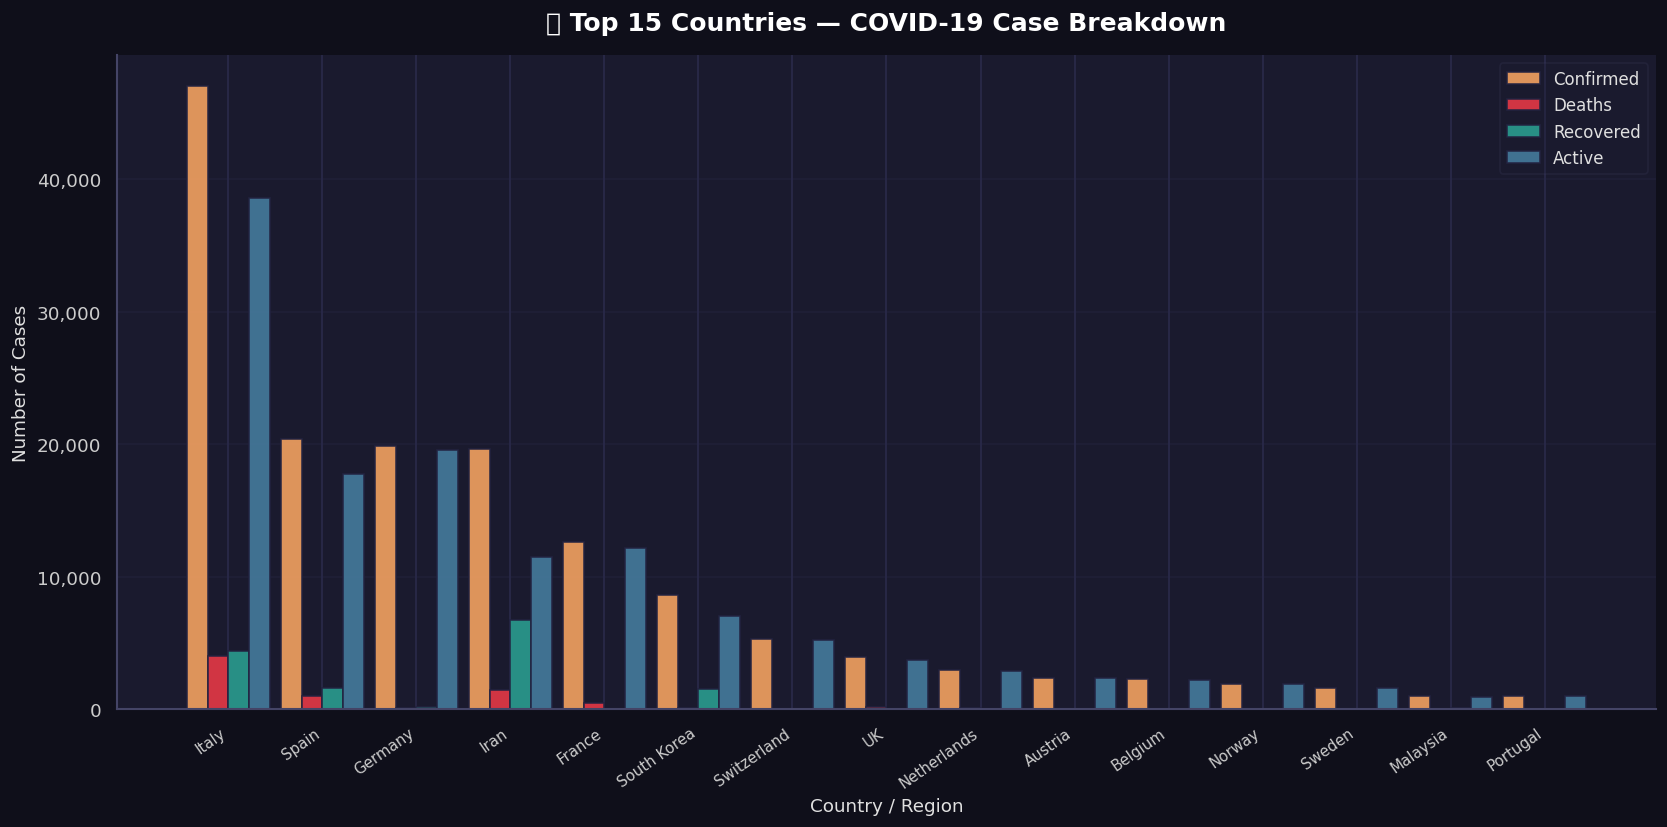

In [8]:
top15 = df_latest.nlargest(15, 'Confirmed')[['Country/Region','Confirmed','Deaths','Recovered','Active']]

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

x = np.arange(len(top15))
width = 0.22

bars1 = ax.bar(x - width*1.5, top15['Confirmed'], width, label='Confirmed',
               color=COLORS['confirmed'], alpha=0.9, edgecolor='#222240')
bars2 = ax.bar(x - width*0.5, top15['Deaths'],    width, label='Deaths',
               color=COLORS['deaths'],    alpha=0.9, edgecolor='#222240')
bars3 = ax.bar(x + width*0.5, top15['Recovered'], width, label='Recovered',
               color=COLORS['recovered'], alpha=0.9, edgecolor='#222240')
bars4 = ax.bar(x + width*1.5, top15['Active'],    width, label='Active',
               color=COLORS['active'],    alpha=0.9, edgecolor='#222240')

ax.set_xticks(x)
ax.set_xticklabels(top15['Country/Region'], rotation=35, ha='right', fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda val, _: f'{int(val):,}'))
ax.set_title('🌍 Top 15 Countries — COVID-19 Case Breakdown', fontsize=15, fontweight='bold',
             color='white', pad=15)
ax.set_xlabel('Country / Region', fontsize=11)
ax.set_ylabel('Number of Cases', fontsize=11)
ax.legend(framealpha=0.2, fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## 🥧 Section 6 — Global Distribution: Confirmed vs Deaths vs Recovered

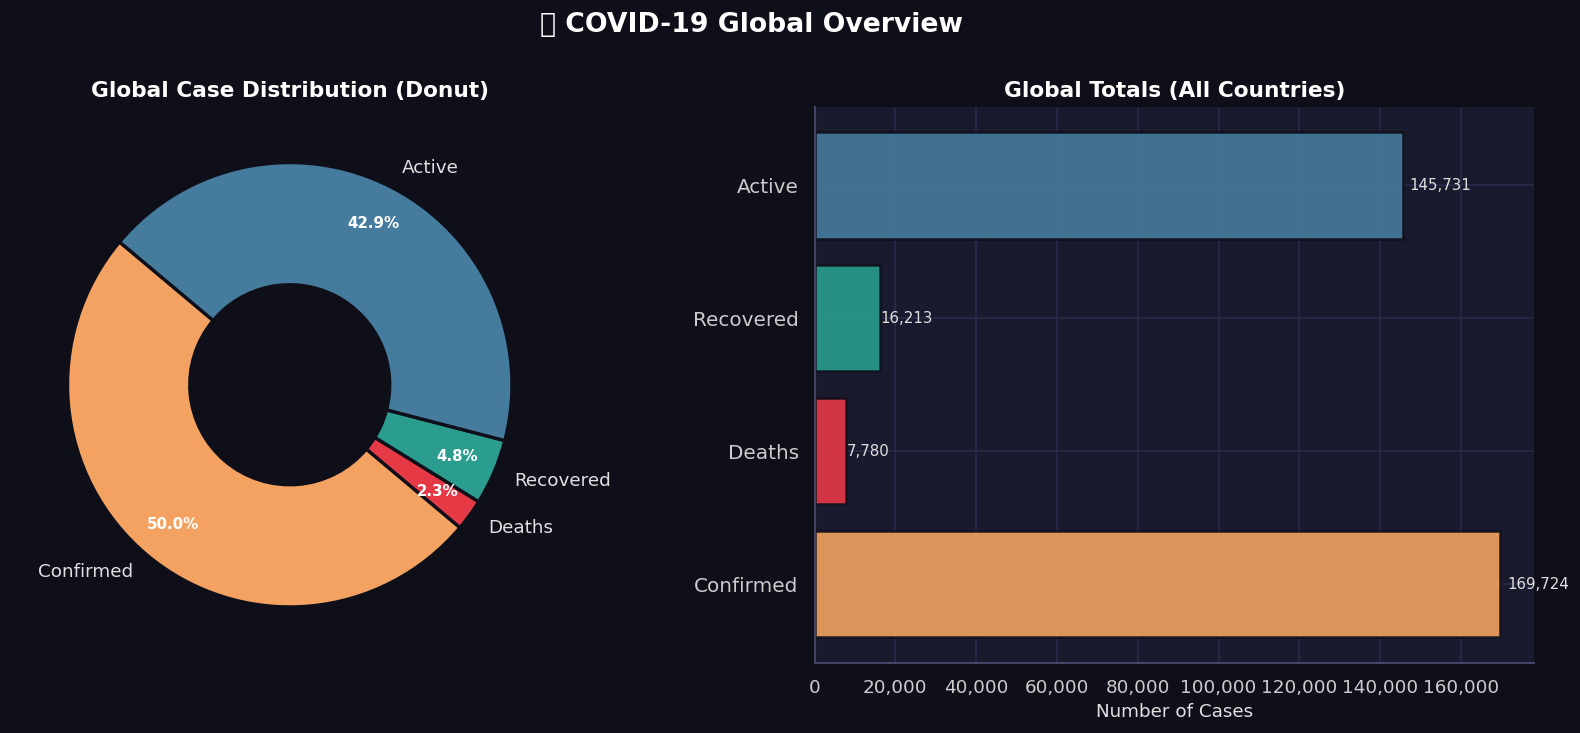

In [9]:
labels  = ['Confirmed', 'Deaths', 'Recovered', 'Active']
sizes   = [total_confirmed, total_deaths, total_recovered, total_active]
palette = [COLORS['confirmed'], COLORS['deaths'], COLORS['recovered'], COLORS['active']]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('#0f0f1a')

# ── Pie chart ────────────────────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#1a1a2e')
wedges, texts, autotexts = ax1.pie(
    sizes, labels=labels, colors=palette,
    autopct='%1.1f%%', startangle=140,
    pctdistance=0.82, wedgeprops=dict(width=0.55, edgecolor='#0f0f1a', linewidth=2)
)
for t in texts:     t.set_color('#e0e0e0'); t.set_fontsize(11)
for at in autotexts: at.set_color('#ffffff'); at.set_fontweight('bold'); at.set_fontsize(9)
ax1.set_title('Global Case Distribution (Donut)', color='white', fontsize=13, fontweight='bold')

# ── Horizontal bar summary ────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
y_pos = np.arange(len(labels))
bars  = ax2.barh(y_pos, sizes, color=palette, edgecolor='#0f0f1a', linewidth=1.5, alpha=0.9)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(labels, fontsize=12)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda val, _: f'{int(val):,}'))
ax2.set_title('Global Totals (All Countries)', color='white', fontsize=13, fontweight='bold')
ax2.set_xlabel('Number of Cases', fontsize=11)
ax2.spines[['top','right']].set_visible(False)
for bar, val in zip(bars, sizes):
    ax2.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', color='#e0e0e0', fontsize=9)

fig.suptitle('🌐 COVID-19 Global Overview', fontsize=16, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.show()

---
## 📈 Section 7 — Global Time-Series Trends

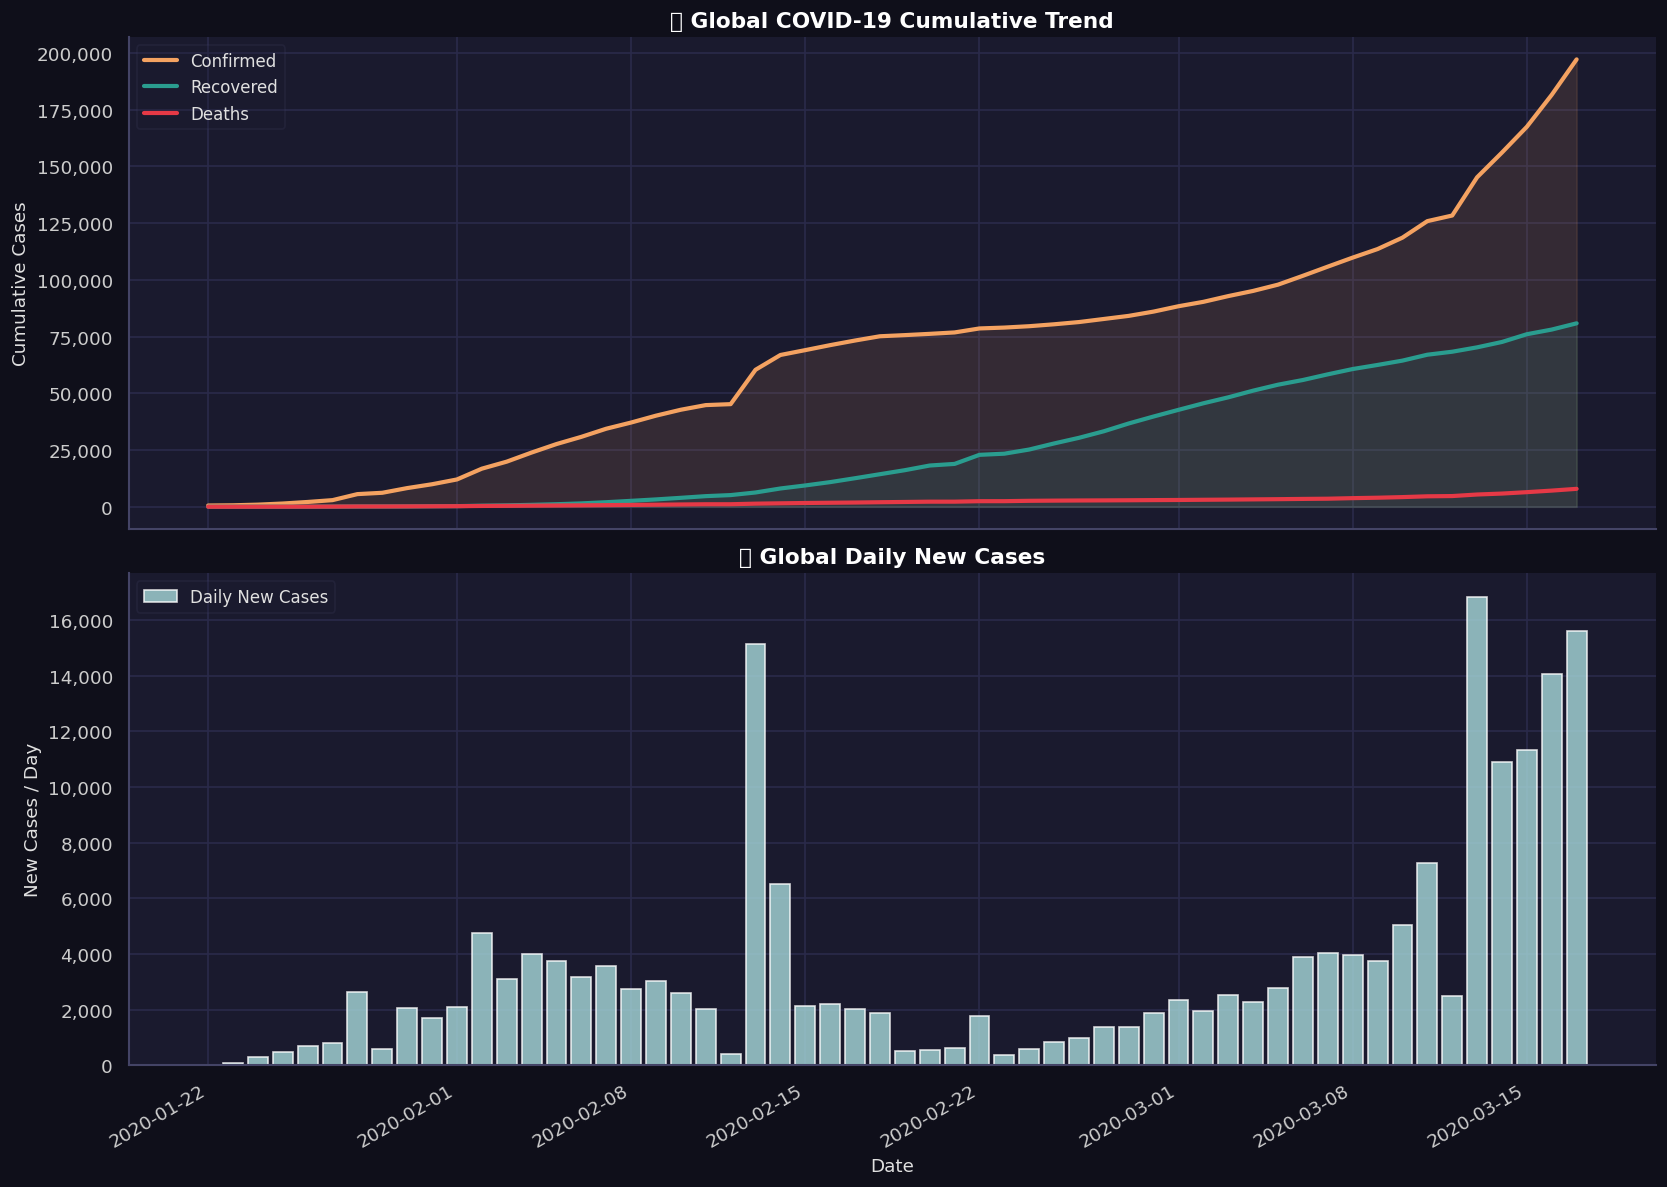

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.patch.set_facecolor('#0f0f1a')

# ── Top: Cumulative trends ────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#1a1a2e')
ax.plot(df_global_daily['Date'], df_global_daily['Confirmed'],
        color=COLORS['confirmed'], linewidth=2.5, label='Confirmed', zorder=3)
ax.plot(df_global_daily['Date'], df_global_daily['Recovered'],
        color=COLORS['recovered'], linewidth=2.5, label='Recovered', zorder=3)
ax.plot(df_global_daily['Date'], df_global_daily['Deaths'],
        color=COLORS['deaths'],    linewidth=2.5, label='Deaths',    zorder=3)
ax.fill_between(df_global_daily['Date'], df_global_daily['Confirmed'],
                alpha=0.12, color=COLORS['confirmed'])
ax.fill_between(df_global_daily['Date'], df_global_daily['Recovered'],
                alpha=0.12, color=COLORS['recovered'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax.set_title('📈 Global COVID-19 Cumulative Trend', color='white', fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Cases', fontsize=11)
ax.legend(fontsize=10, framealpha=0.2)
ax.spines[['top','right']].set_visible(False)

# ── Bottom: Daily new cases ───────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
ax2.bar(df_global_daily['Date'], df_global_daily['New_Cases'],
        color=COLORS['new_cases'], alpha=0.8, label='Daily New Cases', width=0.8)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax2.set_title('📊 Global Daily New Cases', color='white', fontsize=13, fontweight='bold')
ax2.set_ylabel('New Cases / Day', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.legend(fontsize=10, framealpha=0.2)
ax2.spines[['top','right']].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
## 🌡️ Section 8 — Country Comparison: Top 10

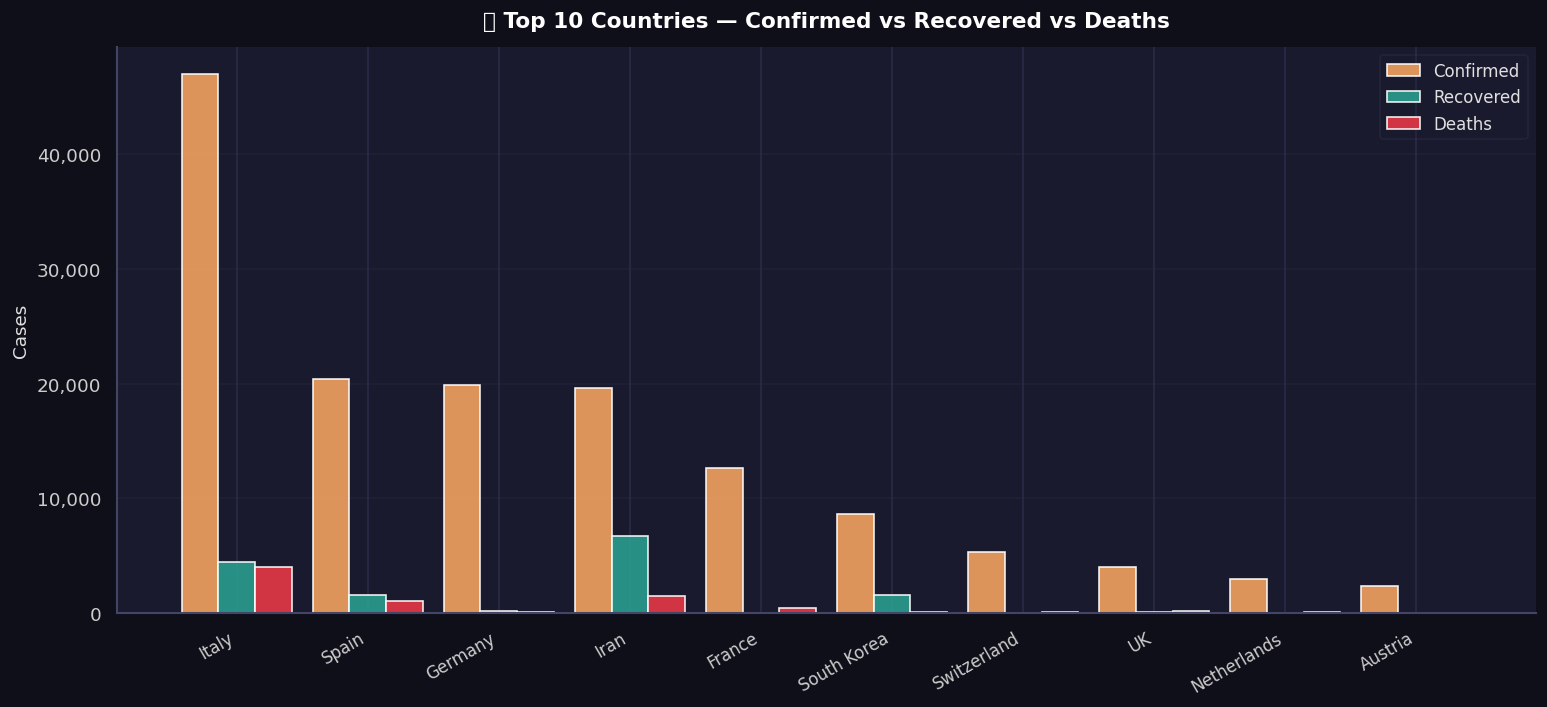

In [11]:
top10 = df_latest.nlargest(10, 'Confirmed')

fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

x     = np.arange(len(top10))
width = 0.28

ax.bar(x - width,     top10['Confirmed'].values, width,
       label='Confirmed', color=COLORS['confirmed'], alpha=0.9)
ax.bar(x,             top10['Recovered'].values,  width,
       label='Recovered', color=COLORS['recovered'], alpha=0.9)
ax.bar(x + width,     top10['Deaths'].values,     width,
       label='Deaths',    color=COLORS['deaths'],    alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(top10['Country/Region'].values, rotation=30, ha='right', fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax.set_title('🌍 Top 10 Countries — Confirmed vs Recovered vs Deaths', fontsize=13,
             fontweight='bold', color='white', pad=12)
ax.set_ylabel('Cases', fontsize=11)
ax.legend(fontsize=10, framealpha=0.2)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## ⚰️ Section 9 — Mortality & Recovery Rate Analysis

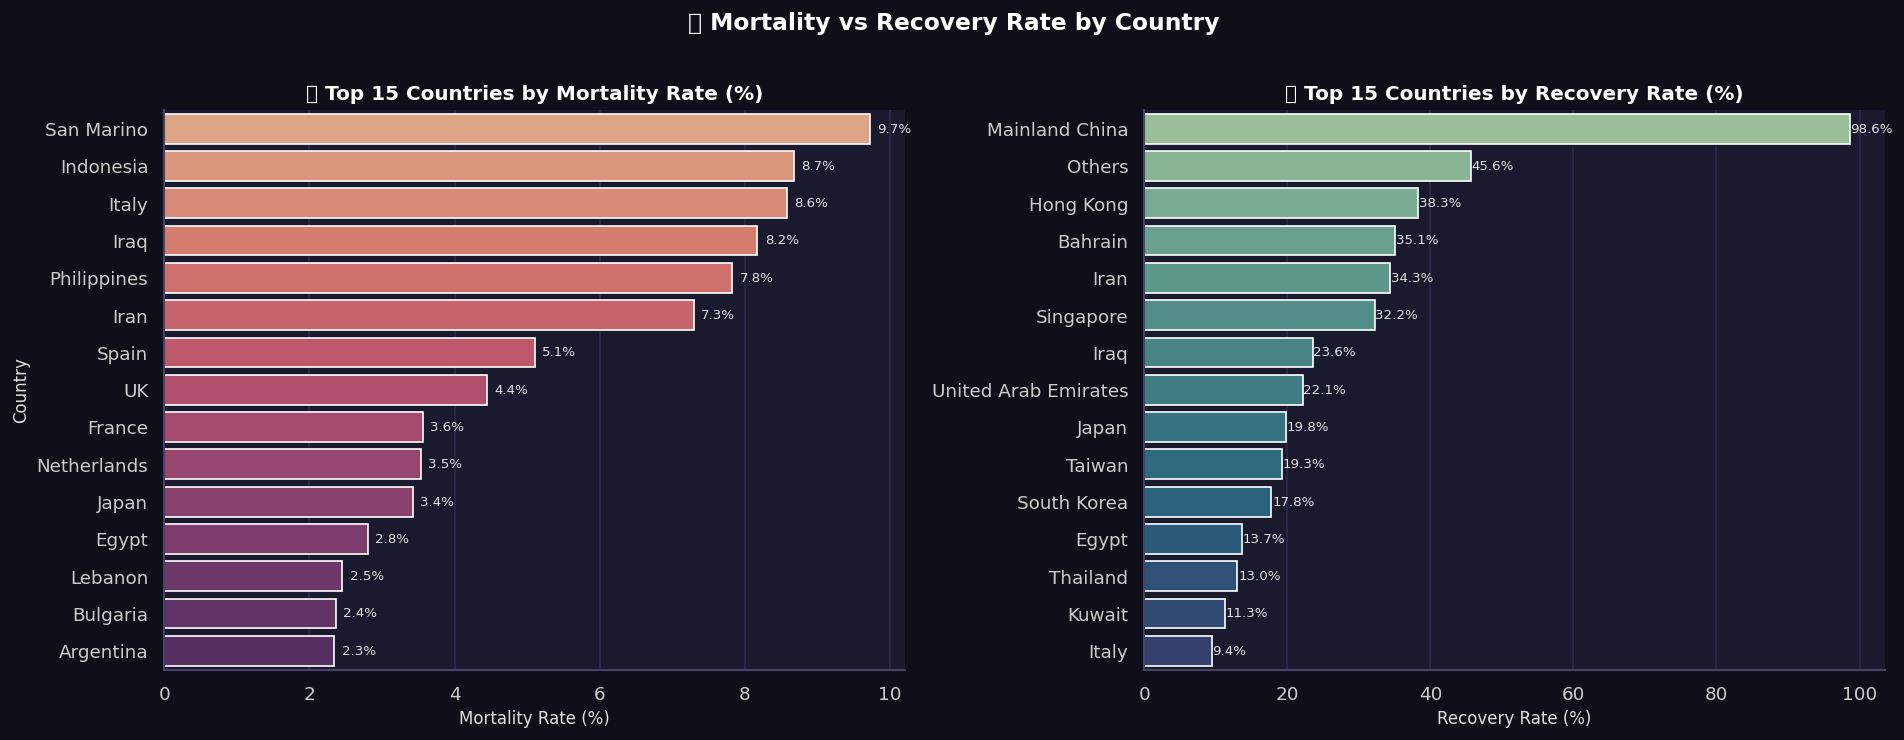

In [12]:
# Countries with at least 100 confirmed cases for meaningful rates
df_rates = df_latest[df_latest['Confirmed'] >= 100].copy()
top_mort  = df_rates.nlargest(15, 'Mortality_Rate')
top_recov = df_rates.nlargest(15, 'Recovery_Rate')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#0f0f1a')

# ── Mortality Rate ────────────────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#1a1a2e')
sns.barplot(data=top_mort, y='Country/Region', x='Mortality_Rate',
            palette='flare', ax=ax1, orient='h')
ax1.set_title('💀 Top 15 Countries by Mortality Rate (%)',
              color='white', fontsize=12, fontweight='bold')
ax1.set_xlabel('Mortality Rate (%)', fontsize=10)
ax1.set_ylabel('Country', fontsize=10)
for p in ax1.patches:
    ax1.text(p.get_width() + 0.1, p.get_y() + p.get_height()/2,
             f'{p.get_width():.1f}%', va='center', color='#e0e0e0', fontsize=8)
ax1.spines[['top','right']].set_visible(False)

# ── Recovery Rate ─────────────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
sns.barplot(data=top_recov, y='Country/Region', x='Recovery_Rate',
            palette='crest', ax=ax2, orient='h')
ax2.set_title('💚 Top 15 Countries by Recovery Rate (%)',
              color='white', fontsize=12, fontweight='bold')
ax2.set_xlabel('Recovery Rate (%)', fontsize=10)
ax2.set_ylabel('')
for p in ax2.patches:
    ax2.text(p.get_width() + 0.1, p.get_y() + p.get_height()/2,
             f'{p.get_width():.1f}%', va='center', color='#e0e0e0', fontsize=8)
ax2.spines[['top','right']].set_visible(False)

fig.suptitle('📊 Mortality vs Recovery Rate by Country', fontsize=14,
             fontweight='bold', color='white', y=1.02)
plt.tight_layout()
plt.show()

---
## 🔥 Section 10 — Correlation Matrix Heatmap

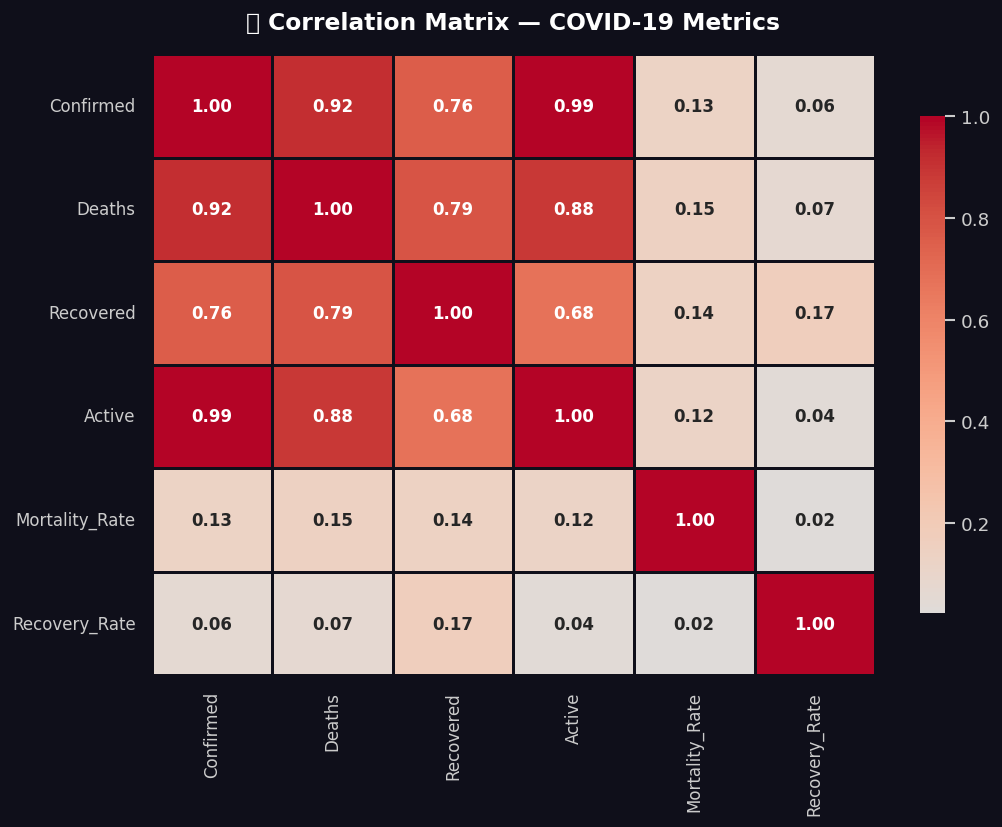


📌 Correlation Insights:
  Confirmed ↔ Deaths: r = 0.92
  Confirmed ↔ Recovered: r = 0.76
  Confirmed ↔ Active: r = 0.99
  Deaths ↔ Recovered: r = 0.79
  Deaths ↔ Active: r = 0.88


In [13]:
corr_cols = ['Confirmed', 'Deaths', 'Recovered', 'Active', 'Mortality_Rate', 'Recovery_Rate']
corr_matrix = df_latest[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)   # show lower triangle + diagonal

heatmap = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.8,
    linecolor='#0f0f1a',
    annot_kws={'size': 10, 'weight': 'bold'},
    ax=ax,
    cbar_kws={'shrink': 0.8}
)

ax.set_title('🔗 Correlation Matrix — COVID-19 Metrics', fontsize=14,
             fontweight='bold', color='white', pad=15)
ax.tick_params(colors='#cccccc', labelsize=10)
heatmap.collections[0].colorbar.ax.yaxis.set_tick_params(color='#cccccc')
plt.setp(plt.getp(heatmap.collections[0].colorbar.ax.axes, 'yticklabels'), color='#cccccc')

plt.tight_layout()
plt.show()

print('\n📌 Correlation Insights:')
high_corr = []
for i in range(len(corr_cols)):
    for j in range(i+1, len(corr_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.7:
            high_corr.append(f'  {corr_cols[i]} ↔ {corr_cols[j]}: r = {r:.2f}')
for h in high_corr:
    print(h)

---
## 📉 Section 11 — Daily Growth Rate Analysis

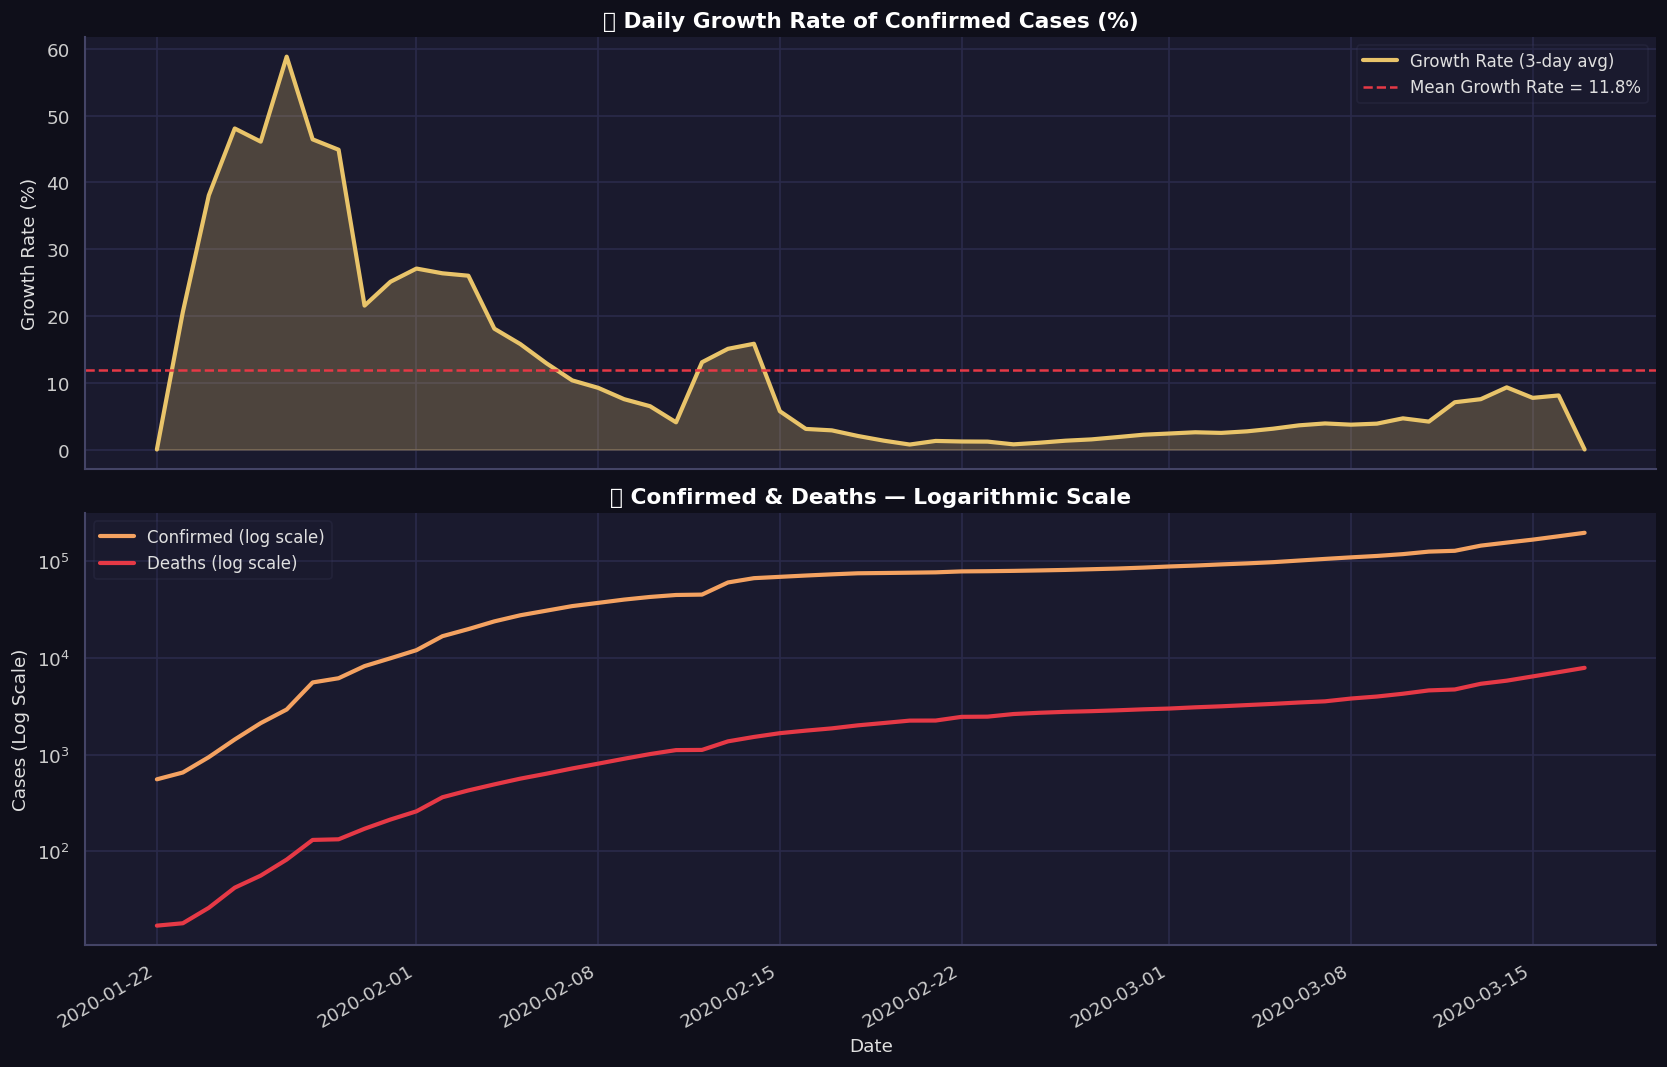

In [14]:
# Smooth growth rate with 3-day rolling average
df_global_daily['Growth_Smooth'] = (
    df_global_daily['Growth_Rate(%)']
    .replace([np.inf, -np.inf], np.nan)
    .rolling(window=3, center=True)
    .mean()
    .fillna(0)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.patch.set_facecolor('#0f0f1a')

# ── Growth Rate Line ──────────────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#1a1a2e')
ax1.plot(df_global_daily['Date'], df_global_daily['Growth_Smooth'],
         color='#e9c46a', linewidth=2.5, label='Growth Rate (3-day avg)')
ax1.fill_between(df_global_daily['Date'], df_global_daily['Growth_Smooth'],
                 alpha=0.25, color='#e9c46a')
ax1.axhline(y=df_global_daily['Growth_Smooth'].mean(), color='#e63946',
            linestyle='--', linewidth=1.5, label=f'Mean Growth Rate = {df_global_daily["Growth_Smooth"].mean():.1f}%')
ax1.set_title('📉 Daily Growth Rate of Confirmed Cases (%)', color='white',
              fontsize=13, fontweight='bold')
ax1.set_ylabel('Growth Rate (%)', fontsize=11)
ax1.legend(fontsize=10, framealpha=0.2)
ax1.spines[['top','right']].set_visible(False)

# ── Log Scale Confirmed ───────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
ax2.semilogy(df_global_daily['Date'], df_global_daily['Confirmed'].replace(0, np.nan),
             color=COLORS['confirmed'], linewidth=2.5, label='Confirmed (log scale)')
ax2.semilogy(df_global_daily['Date'], df_global_daily['Deaths'].replace(0, np.nan),
             color=COLORS['deaths'],    linewidth=2.5, label='Deaths (log scale)')
ax2.set_title('📊 Confirmed & Deaths — Logarithmic Scale', color='white',
              fontsize=13, fontweight='bold')
ax2.set_ylabel('Cases (Log Scale)', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.legend(fontsize=10, framealpha=0.2)
ax2.spines[['top','right']].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
## 🌏 Section 12 — Wide-Format Time-Series: Country Trajectories

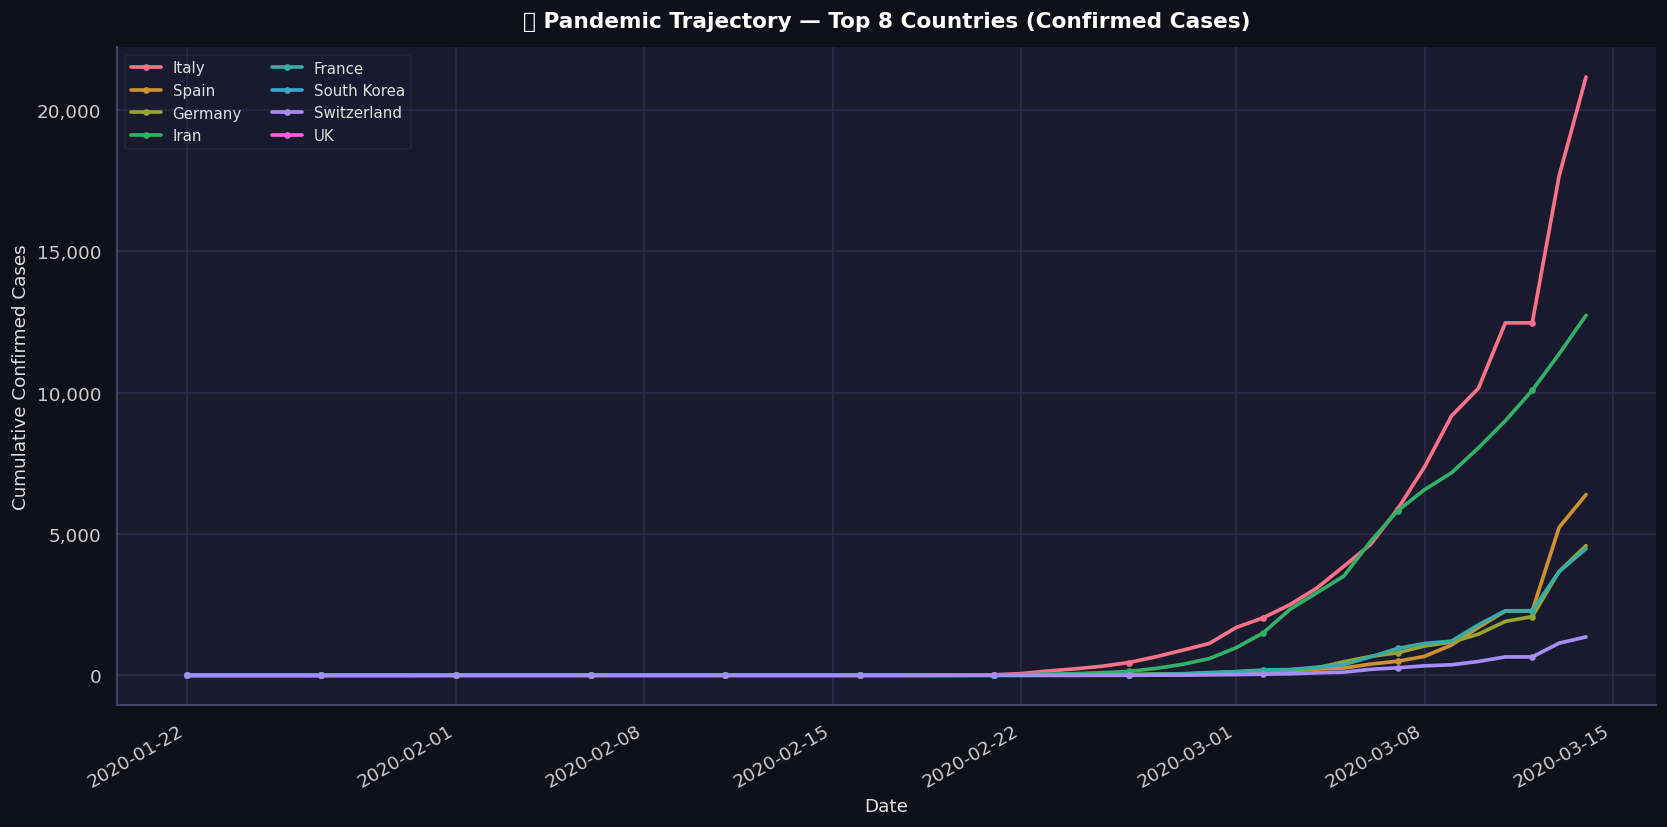

In [ ]:
# Melt wide-format confirmed data to long format
id_cols  = ['Province/State', 'Country/Region', 'Lat', 'Long']
date_cols_conf = [c for c in df_conf.columns if c not in id_cols]

df_conf_long = df_conf.melt(id_vars=id_cols, value_vars=date_cols_conf,
                            var_name='Date', value_name='Confirmed')
df_conf_long['Date'] = pd.to_datetime(df_conf_long['Date'])
df_conf_long['Confirmed'] = pd.to_numeric(df_conf_long['Confirmed'], errors='coerce').fillna(0)

# Top 8 countries trajectory
top8_countries = df_latest.nlargest(8, 'Confirmed')['Country/Region'].tolist()

df_traj = (
    df_conf_long[df_conf_long['Country/Region'].isin(top8_countries)]
    .groupby(['Country/Region', 'Date'])['Confirmed']
    .sum()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

palette8 = sns.color_palette('husl', 8)
for i, country in enumerate(top8_countries):
    cdata = df_traj[df_traj['Country/Region'] == country]
    ax.plot(cdata['Date'], cdata['Confirmed'],
            label=country, linewidth=2.2, color=palette8[i], marker='o',
            markersize=3, markevery=5)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax.set_title('🌏 Pandemic Trajectory — Top 8 Countries (Confirmed Cases)', fontsize=13,
             fontweight='bold', color='white', pad=12)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Cumulative Confirmed Cases', fontsize=11)
ax.legend(fontsize=9, framealpha=0.2, ncol=2)
ax.spines[['top','right']].set_visible(False)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
## 🇮🇳 Section 13 — India State-wise COVID-19 Analysis

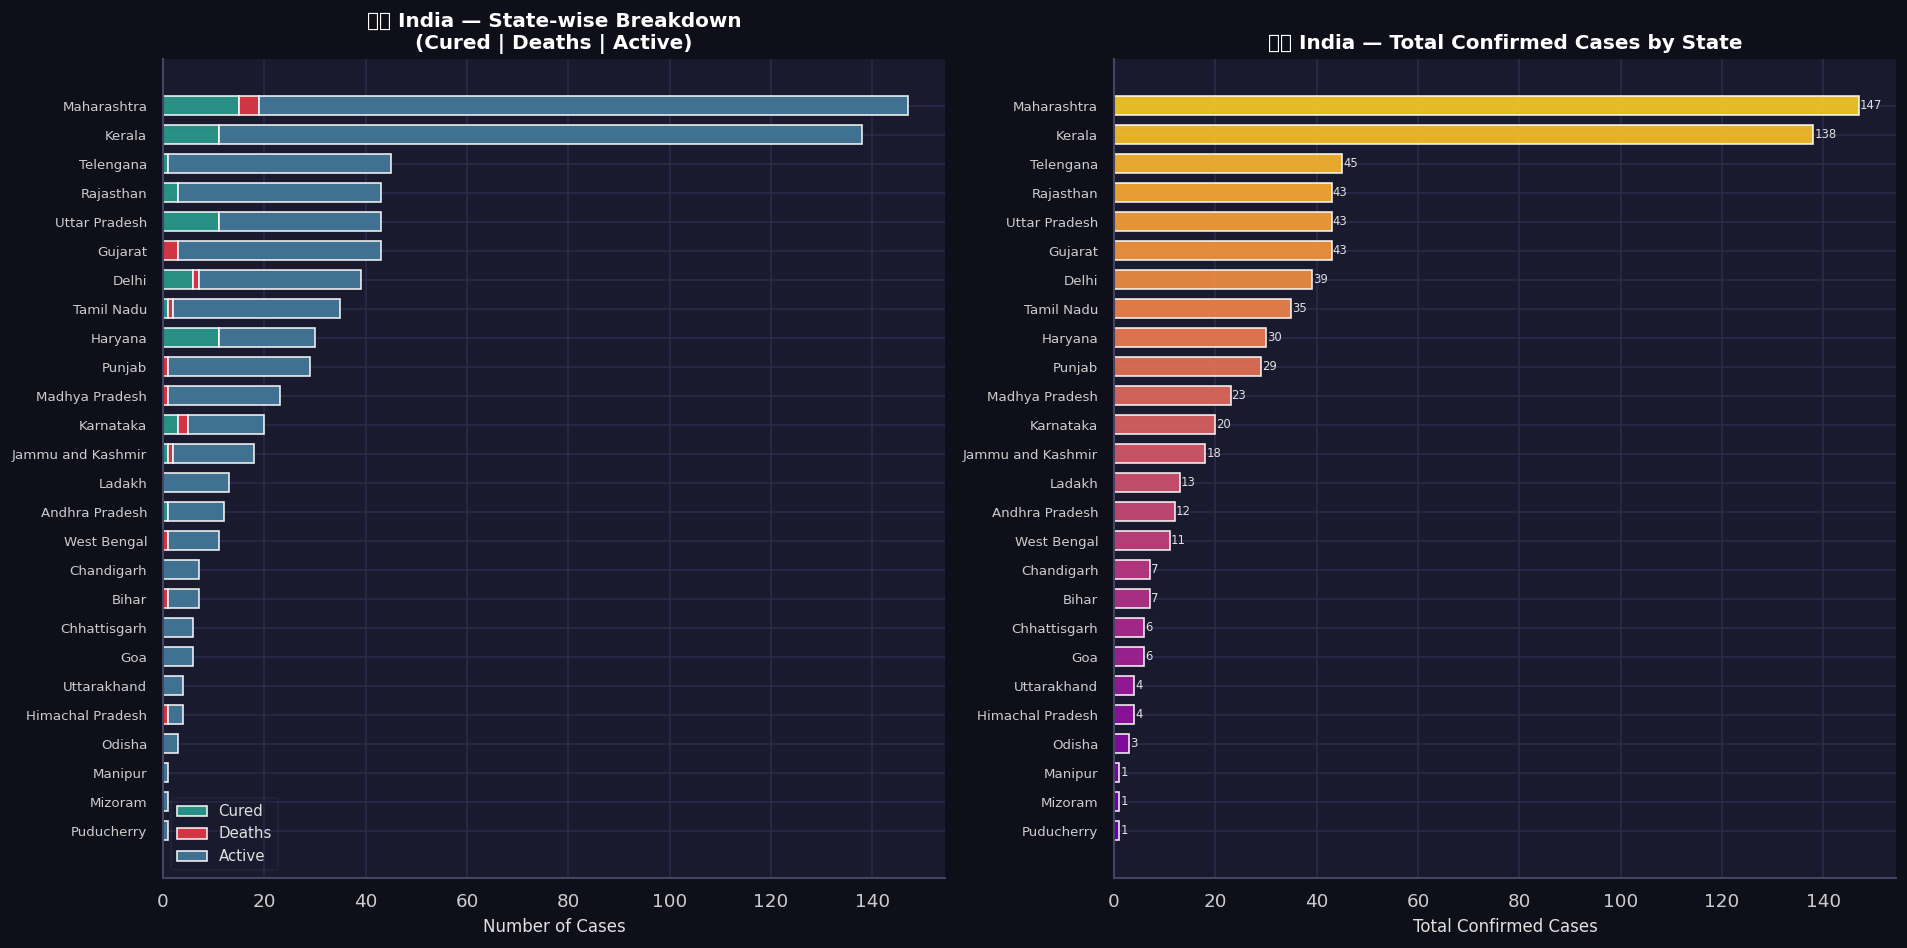

In [16]:
df_india_sorted = df_india.sort_values('Total_Confirmed', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('#0f0f1a')

# ── Stacked bar: Confirmed breakdown ──────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#1a1a2e')
y_pos = np.arange(len(df_india_sorted))

ax1.barh(y_pos, df_india_sorted['Cured'],          color=COLORS['recovered'],
         label='Cured',   alpha=0.9, height=0.65)
ax1.barh(y_pos, df_india_sorted['Deaths'],          color=COLORS['deaths'],
         label='Deaths',  alpha=0.9, height=0.65,
         left=df_india_sorted['Cured'].values)
ax1.barh(y_pos, df_india_sorted['Active'],          color=COLORS['active'],
         label='Active',  alpha=0.9, height=0.65,
         left=(df_india_sorted['Cured'] + df_india_sorted['Deaths']).values)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_india_sorted['State'], fontsize=8)
ax1.set_xlabel('Number of Cases', fontsize=10)
ax1.set_title('🇮🇳 India — State-wise Breakdown\n(Cured | Deaths | Active)',
              color='white', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9, framealpha=0.2)
ax1.spines[['top','right']].set_visible(False)

# ── Total confirmed bar ────────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
colors_india = plt.cm.plasma(np.linspace(0.2, 0.9, len(df_india_sorted)))
bars = ax2.barh(y_pos, df_india_sorted['Total_Confirmed'],
                color=colors_india, height=0.65, alpha=0.9)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(df_india_sorted['State'], fontsize=8)
ax2.set_xlabel('Total Confirmed Cases', fontsize=10)
ax2.set_title('🇮🇳 India — Total Confirmed Cases by State',
              color='white', fontsize=12, fontweight='bold')
for bar, val in zip(bars, df_india_sorted['Total_Confirmed']):
    ax2.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             str(val), va='center', color='#e0e0e0', fontsize=7)
ax2.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## 📅 Section 14 — India Per-Day Growth Trend

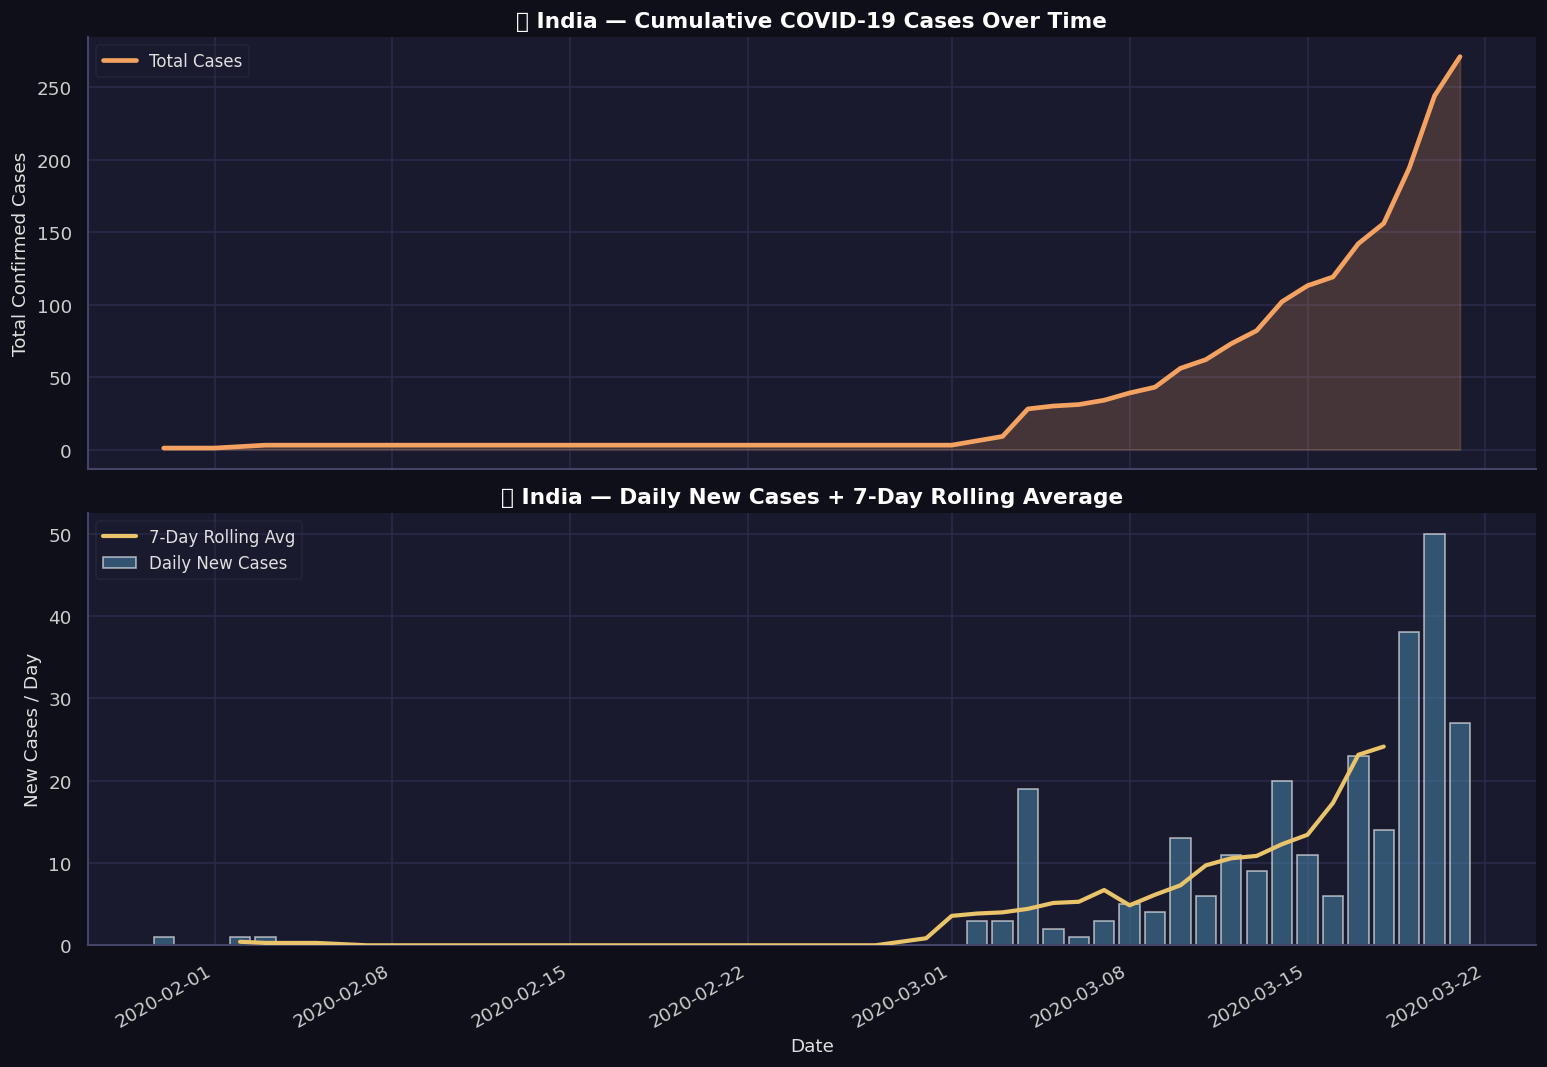

In [17]:
# Rolling 7-day average of new cases
df_perday['Rolling_7'] = df_perday['New_Cases'].rolling(window=7, center=True).mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
fig.patch.set_facecolor('#0f0f1a')

# ── Cumulative total ──────────────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#1a1a2e')
ax1.plot(df_perday['Date'], df_perday['Total_Cases'],
         color=COLORS['confirmed'], linewidth=2.8, label='Total Cases', zorder=3)
ax1.fill_between(df_perday['Date'], df_perday['Total_Cases'],
                 alpha=0.2, color=COLORS['confirmed'])
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax1.set_title('📈 India — Cumulative COVID-19 Cases Over Time',
              color='white', fontsize=13, fontweight='bold')
ax1.set_ylabel('Total Confirmed Cases', fontsize=11)
ax1.legend(fontsize=10, framealpha=0.2)
ax1.spines[['top','right']].set_visible(False)

# ── Daily new cases + rolling average ────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
ax2.bar(df_perday['Date'], df_perday['New_Cases'],
        color=COLORS['active'], alpha=0.6, label='Daily New Cases', width=0.8)
ax2.plot(df_perday['Date'], df_perday['Rolling_7'],
         color='#e9c46a', linewidth=2.5, label='7-Day Rolling Avg', zorder=3)
ax2.set_title('📊 India — Daily New Cases + 7-Day Rolling Average',
              color='white', fontsize=13, fontweight='bold')
ax2.set_ylabel('New Cases / Day', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.legend(fontsize=10, framealpha=0.2)
ax2.spines[['top','right']].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
## 🗺️ Section 15 — India Geographical Scatter Map (Lat/Long Bubble)

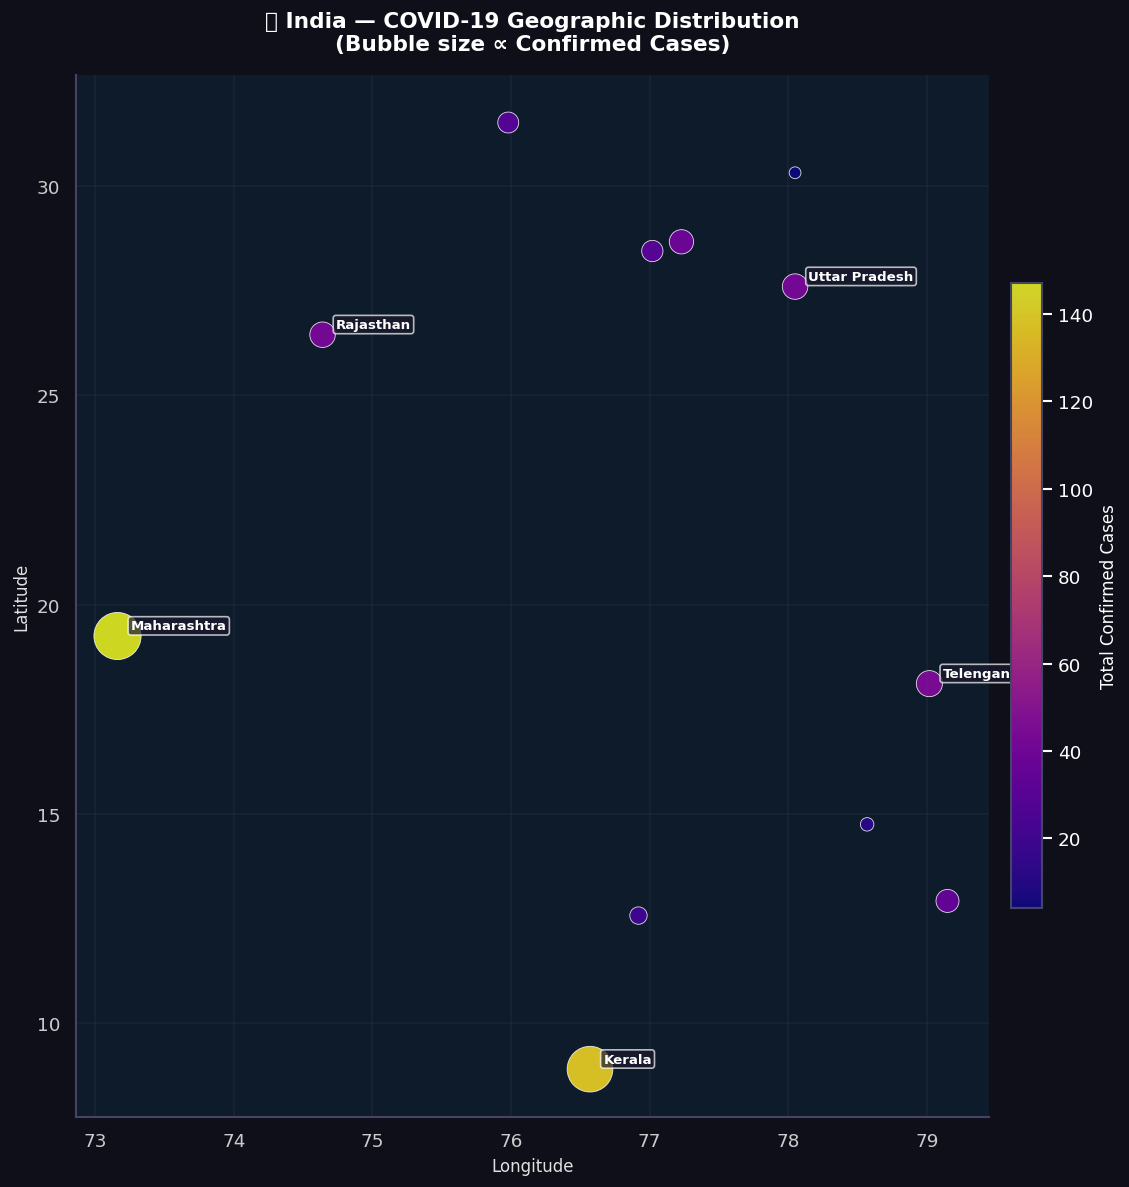

In [18]:
df_geo = df_india_geo.dropna(subset=['Latitude', 'Longitude']).copy()

# Bubble size proportional to confirmed cases (min size = 50)
max_cases   = df_geo['Total_Confirmed'].max()
bubble_size = ((df_geo['Total_Confirmed'] / max_cases) * 800).clip(lower=50)

fig, ax = plt.subplots(figsize=(10, 10))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0d1b2a')

scatter = ax.scatter(
    df_geo['Longitude'], df_geo['Latitude'],
    s=bubble_size,
    c=df_geo['Total_Confirmed'],
    cmap='plasma',
    alpha=0.85,
    edgecolors='white',
    linewidths=0.5,
    zorder=3
)

# Annotate top-5 states
top5_geo = df_geo.nlargest(5, 'Total_Confirmed')
for _, row in top5_geo.iterrows():
    ax.annotate(
        row['State'],
        xy=(row['Longitude'], row['Latitude']),
        xytext=(8, 4), textcoords='offset points',
        color='white', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7)
    )

cbar = plt.colorbar(scatter, ax=ax, pad=0.02, shrink=0.6)
cbar.set_label('Total Confirmed Cases', color='white', fontsize=10)
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

ax.set_title('🗺️ India — COVID-19 Geographic Distribution\n(Bubble size ∝ Confirmed Cases)',
             color='white', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Longitude', fontsize=10)
ax.set_ylabel('Latitude', fontsize=10)
ax.grid(alpha=0.2, color='#444466')
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## 🌡️ Section 16 — Seaborn Heatmap: India Weekly Case Intensity

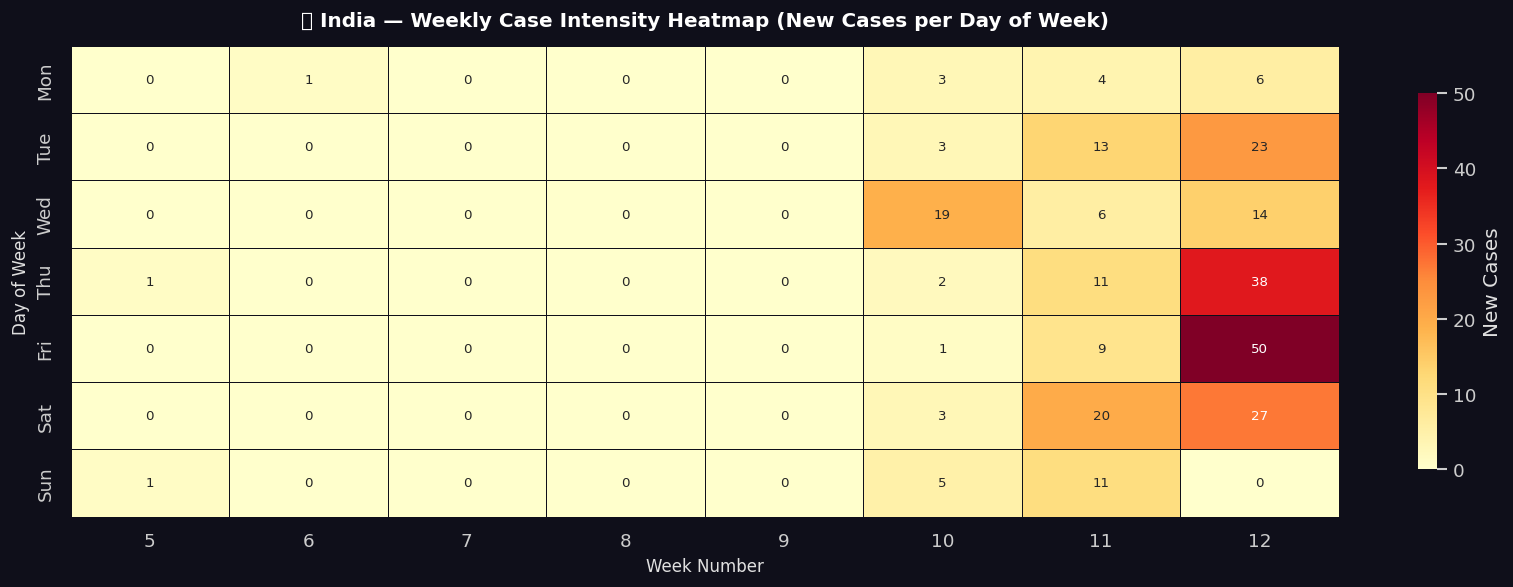

In [19]:
# Create week x day pivot for heatmap
df_heat = df_perday[['Date', 'New_Cases']].copy()
df_heat['Week']    = df_heat['Date'].dt.isocalendar().week.astype(int)
df_heat['DayName'] = df_heat['Date'].dt.strftime('%a')   # Mon, Tue …

day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
pivot = df_heat.pivot_table(index='DayName', columns='Week',
                            values='New_Cases', aggfunc='sum').reindex(day_order)
pivot = pivot.fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

sns.heatmap(
    pivot,
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='#0f0f1a',
    annot=True,
    fmt='d',
    annot_kws={'size': 8},
    ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'New Cases'}
)

ax.set_title('🌡️ India — Weekly Case Intensity Heatmap (New Cases per Day of Week)',
             color='white', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Week Number', fontsize=10)
ax.set_ylabel('Day of Week', fontsize=10)
ax.tick_params(colors='#cccccc')

plt.tight_layout()
plt.show()

---
## 📊 Section 17 — Seaborn Distribution & Statistical Plots

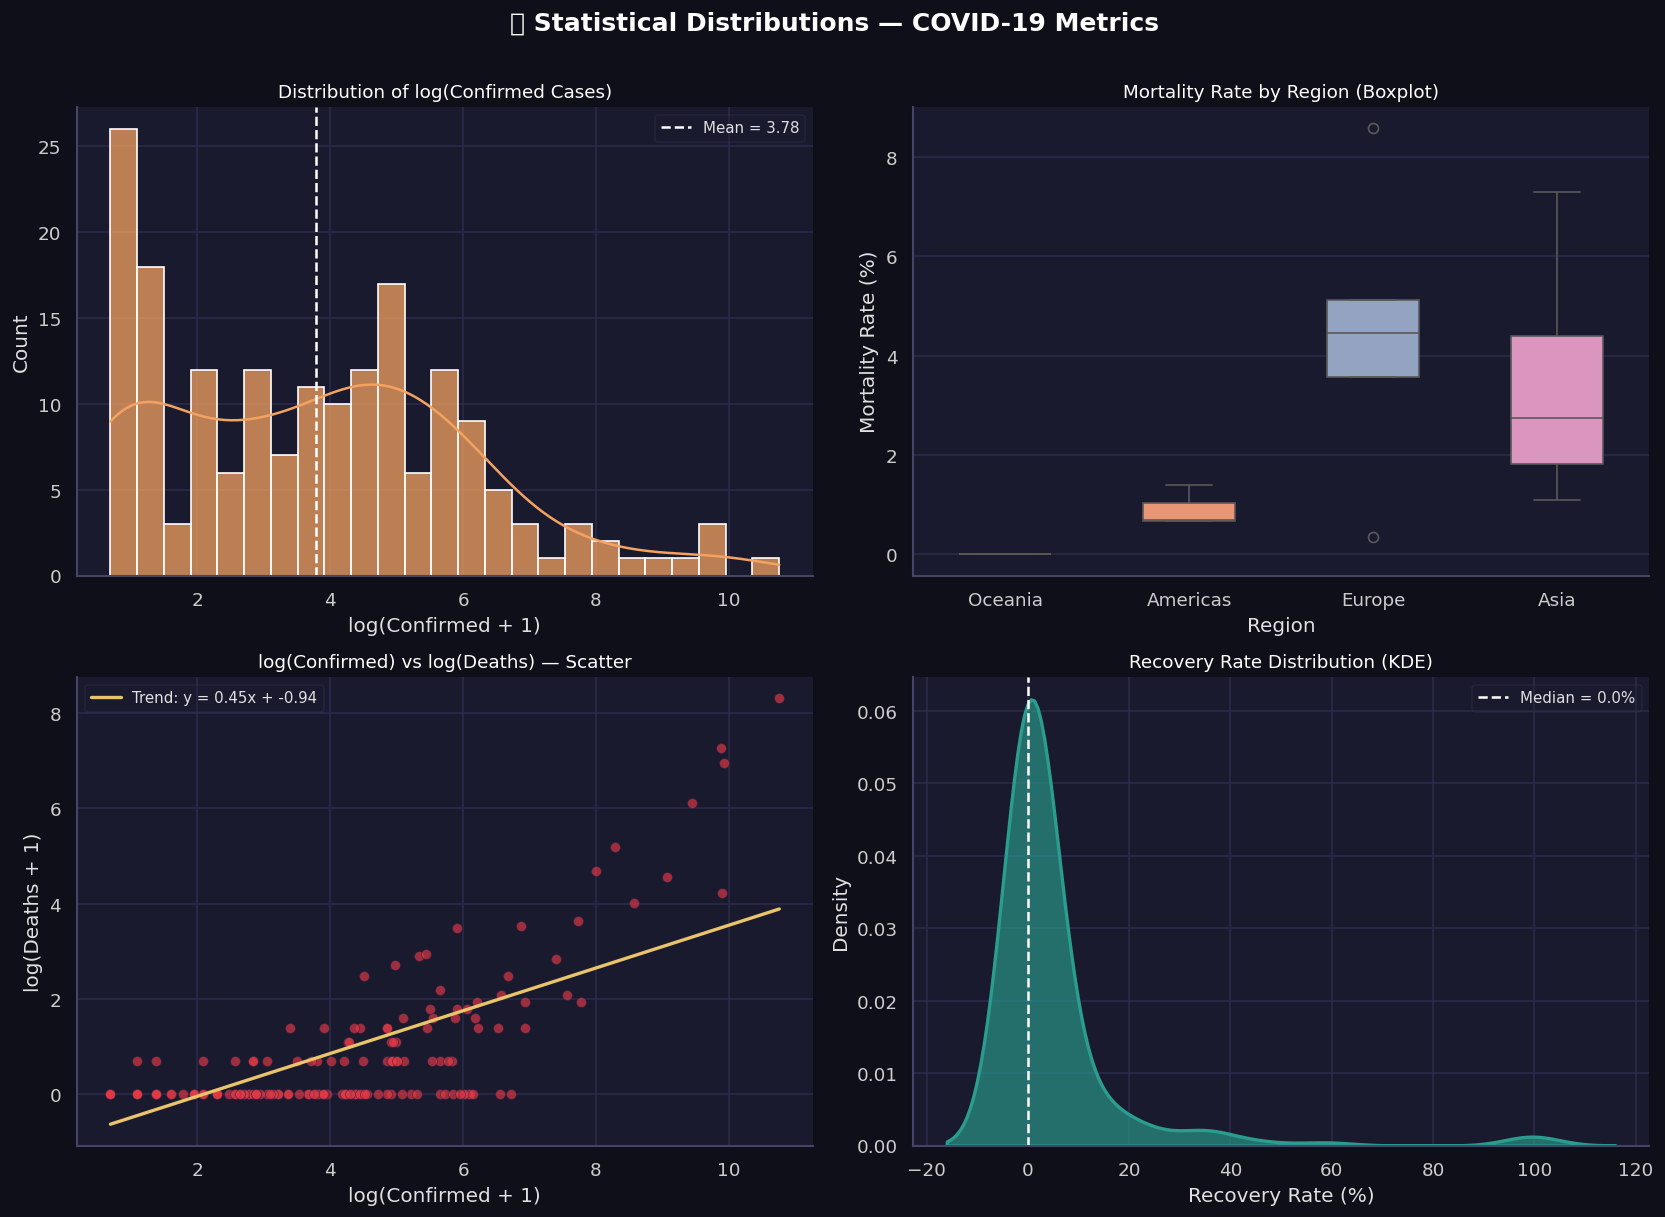

In [20]:
df_nonzero = df_latest[df_latest['Confirmed'] > 0].copy()
df_nonzero['log_Confirmed'] = np.log1p(df_nonzero['Confirmed'])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('📊 Statistical Distributions — COVID-19 Metrics', fontsize=15,
             fontweight='bold', color='white', y=1.01)

# ── KDE: Distribution of confirmed cases (log) ────────────────────────────────
ax = axes[0, 0]
ax.set_facecolor('#1a1a2e')
sns.histplot(df_nonzero['log_Confirmed'], kde=True, ax=ax,
             color=COLORS['confirmed'], bins=25, alpha=0.75)
ax.axvline(df_nonzero['log_Confirmed'].mean(), color='white', linestyle='--', linewidth=1.5,
           label=f'Mean = {df_nonzero["log_Confirmed"].mean():.2f}')
ax.set_title('Distribution of log(Confirmed Cases)', color='white', fontsize=11)
ax.set_xlabel('log(Confirmed + 1)'); ax.set_ylabel('Count')
ax.legend(fontsize=9, framealpha=0.2)
ax.spines[['top','right']].set_visible(False)

# ── Box plot: Mortality Rate by top regions ───────────────────────────────────
ax = axes[0, 1]
ax.set_facecolor('#1a1a2e')
region_map = {
    'China': 'Asia', 'Iran': 'Asia', 'South Korea': 'Asia', 'Japan': 'Asia',
    'India': 'Asia', 'Italy': 'Europe', 'Spain': 'Europe', 'Germany': 'Europe',
    'France': 'Europe', 'UK': 'Europe', 'US': 'Americas', 'Brazil': 'Americas',
    'Canada': 'Americas', 'Australia': 'Oceania'
}
df_region = df_nonzero[df_nonzero['Country/Region'].isin(region_map.keys())].copy()
df_region['Region'] = df_region['Country/Region'].map(region_map)
sns.boxplot(data=df_region, x='Region', y='Mortality_Rate', ax=ax,
            palette='Set2', width=0.5)
ax.set_title('Mortality Rate by Region (Boxplot)', color='white', fontsize=11)
ax.set_ylabel('Mortality Rate (%)')
ax.spines[['top','right']].set_visible(False)

# ── Scatter: Confirmed vs Deaths ──────────────────────────────────────────────
ax = axes[1, 0]
ax.set_facecolor('#1a1a2e')
ax.scatter(np.log1p(df_nonzero['Confirmed']), np.log1p(df_nonzero['Deaths']),
           alpha=0.65, color=COLORS['deaths'], s=35, edgecolors='#222240', linewidths=0.4)
# Regression line using NumPy polyfit
x_data = np.log1p(df_nonzero['Confirmed'].values)
y_data = np.log1p(df_nonzero['Deaths'].values)
mask   = np.isfinite(x_data) & np.isfinite(y_data)
coef   = np.polyfit(x_data[mask], y_data[mask], 1)
poly   = np.poly1d(coef)
x_line = np.linspace(x_data.min(), x_data.max(), 300)
ax.plot(x_line, poly(x_line), color='#e9c46a', linewidth=2,
        label=f'Trend: y = {coef[0]:.2f}x + {coef[1]:.2f}')
ax.set_title('log(Confirmed) vs log(Deaths) — Scatter', color='white', fontsize=11)
ax.set_xlabel('log(Confirmed + 1)'); ax.set_ylabel('log(Deaths + 1)')
ax.legend(fontsize=9, framealpha=0.2)
ax.spines[['top','right']].set_visible(False)

# ── KDE: Recovery Rate distribution ──────────────────────────────────────────
ax = axes[1, 1]
ax.set_facecolor('#1a1a2e')
sns.kdeplot(df_nonzero['Recovery_Rate'], fill=True, color=COLORS['recovered'],
            alpha=0.65, ax=ax, linewidth=2)
ax.axvline(df_nonzero['Recovery_Rate'].median(), color='white',
           linestyle='--', linewidth=1.5,
           label=f'Median = {df_nonzero["Recovery_Rate"].median():.1f}%')
ax.set_title('Recovery Rate Distribution (KDE)', color='white', fontsize=11)
ax.set_xlabel('Recovery Rate (%)')
ax.legend(fontsize=9, framealpha=0.2)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## 🔑 Section 18 — Key Insights & Summary

In [21]:
# ── Compute summary statistics for insight printing ────────────────────────────
top_country         = df_latest.nlargest(1, 'Confirmed')['Country/Region'].values[0]
top_country_cases   = df_latest.nlargest(1, 'Confirmed')['Confirmed'].values[0]
highest_mort        = df_rates.nlargest(1, 'Mortality_Rate')[['Country/Region','Mortality_Rate']]
highest_recov       = df_rates.nlargest(1, 'Recovery_Rate')[['Country/Region','Recovery_Rate']]
global_mort_rate    = round(total_deaths / total_confirmed * 100, 2)
global_recov_rate   = round(total_recovered / total_confirmed * 100, 2)
peak_growth_day     = df_global_daily.loc[df_global_daily['New_Cases'].idxmax(), 'Date']
peak_growth_val     = int(df_global_daily['New_Cases'].max())
india_top_state     = df_india.nlargest(1,'Total_Confirmed')['State'].values[0]
india_top_state_val = int(df_india.nlargest(1,'Total_Confirmed')['Total_Confirmed'].values[0])

print('=' * 65)
print('  🦠 COVID-19 DATA ANALYSIS — KEY INSIGHTS SUMMARY')
print('=' * 65)
print(f'\n  🌍 GLOBAL OVERVIEW')
print(f'     • Total Confirmed (Global)   : {total_confirmed:>12,}')
print(f'     • Total Deaths               : {total_deaths:>12,}')
print(f'     • Total Recovered            : {total_recovered:>12,}')
print(f'     • Global Mortality Rate      : {global_mort_rate:>11.2f}%')
print(f'     • Global Recovery Rate       : {global_recov_rate:>11.2f}%')

print(f'\n  🏆 COUNTRY HIGHLIGHTS')
print(f'     • Highest Confirmed Cases    : {top_country} ({top_country_cases:,})')
print(f'     • Highest Mortality Rate     : {highest_mort["Country/Region"].values[0]} ({highest_mort["Mortality_Rate"].values[0]:.1f}%)')
print(f'     • Highest Recovery Rate      : {highest_recov["Country/Region"].values[0]} ({highest_recov["Recovery_Rate"].values[0]:.1f}%)')

print(f'\n  📈 GROWTH & TRENDS')
print(f'     • Peak Daily New Cases On    : {peak_growth_day.date()} ({peak_growth_val:,} new cases)')
print(f'     • Avg Daily Growth Rate      : {df_global_daily["Growth_Smooth"].mean():.1f}% (3-day smoothed)')

print(f'\n  🇮🇳 INDIA INSIGHTS')
print(f'     • Most Affected State        : {india_top_state} ({india_top_state_val:,} confirmed)')
print(f'     • Total India Confirmed      : {df_india["Total_Confirmed"].sum():,}')
print(f'     • Total India Cured          : {df_india["Cured"].sum():,}')
print(f'     • Total India Deaths         : {df_india["Deaths"].sum():,}')

print(f'\n  🔗 CORRELATIONS')
r_conf_deaths = corr_matrix.loc['Confirmed','Deaths']
r_conf_recov  = corr_matrix.loc['Confirmed','Recovered']
print(f'     • Confirmed ↔ Deaths         : r = {r_conf_deaths:.3f} (very strong)')
print(f'     • Confirmed ↔ Recovered      : r = {r_conf_recov:.3f}')

print('\n' + '=' * 65)
print('  Analysis complete. Data range: Jan 22, 2020 → Mar 20, 2020')
print('=' * 65)

  🦠 COVID-19 DATA ANALYSIS — KEY INSIGHTS SUMMARY

  🌍 GLOBAL OVERVIEW
     • Total Confirmed (Global)   :      169,724
     • Total Deaths               :        7,780
     • Total Recovered            :       16,213
     • Global Mortality Rate      :        4.58%
     • Global Recovery Rate       :        9.55%

  🏆 COUNTRY HIGHLIGHTS
     • Highest Confirmed Cases    : Italy (47,021)
     • Highest Mortality Rate     : San Marino (9.7%)
     • Highest Recovery Rate      : Mainland China (98.6%)

  📈 GROWTH & TRENDS
     • Peak Daily New Cases On    : 2020-03-13 (16,850 new cases)
     • Avg Daily Growth Rate      : 11.8% (3-day smoothed)

  🇮🇳 INDIA INSIGHTS
     • Most Affected State        : Maharashtra (147 confirmed)
     • Total India Confirmed      : 729
     • Total India Cured          : 64
     • Total India Deaths         : 17

  🔗 CORRELATIONS
     • Confirmed ↔ Deaths         : r = 0.919 (very strong)
     • Confirmed ↔ Recovered      : r = 0.761

  Analysis complete. D

---

## ✅ Analysis Complete

This notebook performed a comprehensive COVID-19 data analysis using **Pandas**, **NumPy**, **Matplotlib**, and **Seaborn** across:

| Section | Topic |
|---------|-------|
| 1–2 | Setup, imports, data loading (8 files) |
| 3 | Data cleaning — nulls, dates, duplicates, feature engineering |
| 4 | Descriptive statistics (NumPy + Pandas) |
| 5 | Top 15 countries grouped bar chart |
| 6 | Global donut pie + horizontal bar |
| 7 | Time-series cumulative + daily new cases |
| 8 | Country comparison (Top 10) |
| 9 | Mortality & recovery rate (Seaborn barplot) |
| 10 | Correlation heatmap (Seaborn) |
| 11 | Growth rate + log-scale trend |
| 12 | Country pandemic trajectories (wide-format data) |
| 13 | India state-wise stacked bar |
| 14 | India per-day line + 7-day rolling avg |
| 15 | India geographic scatter map (lat/long) |
| 16 | India weekly intensity heatmap |
| 17 | Statistical distributions (hist, KDE, box, scatter + regression) |
| 18 | Key insights summary |

---
*Author: **Vatsal Gajera** | COVID-19 Analytics Dashboard*